Mounted at /content/drive
Processing: TRAINING1.tif


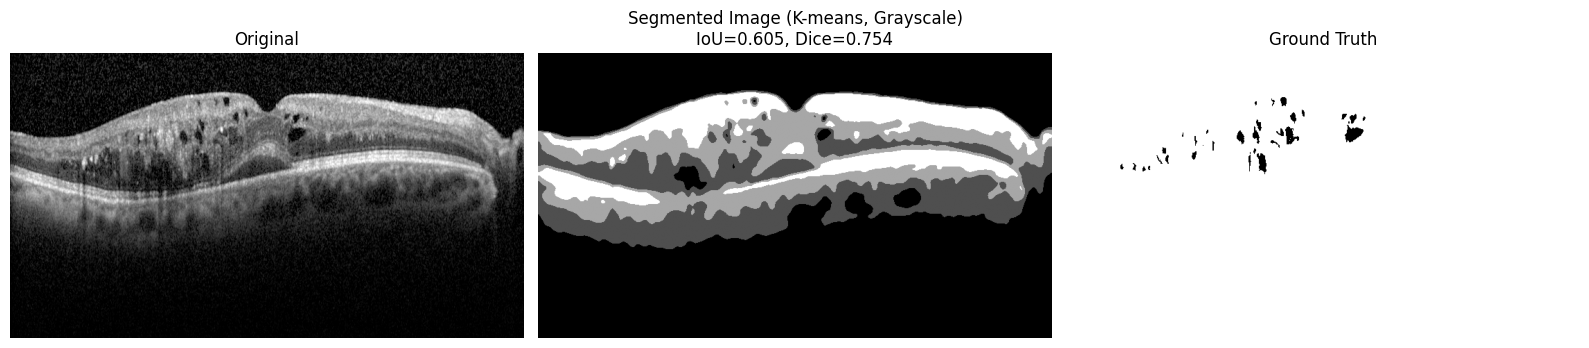

Processing: TRAINING10.tif


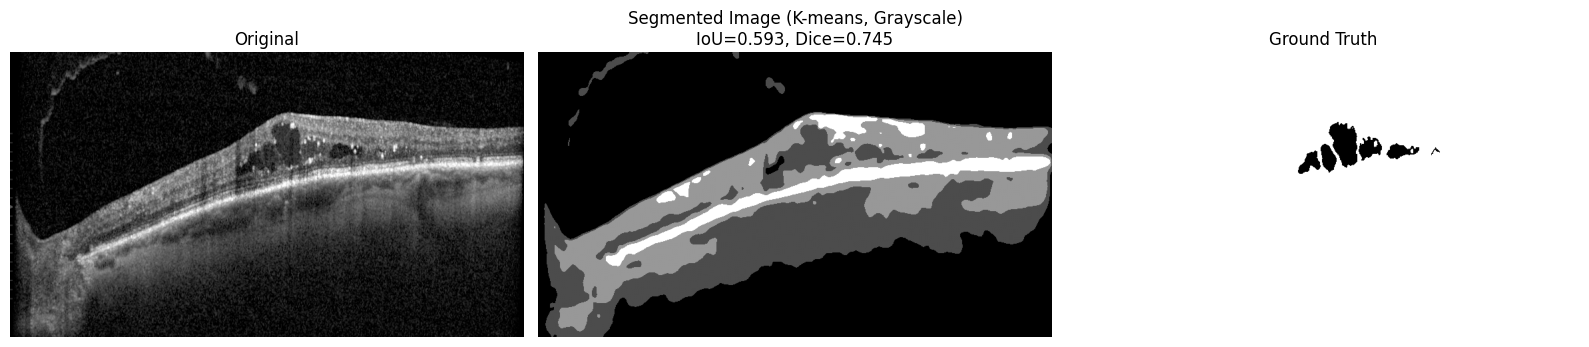

Processing: TRAINING2.tif


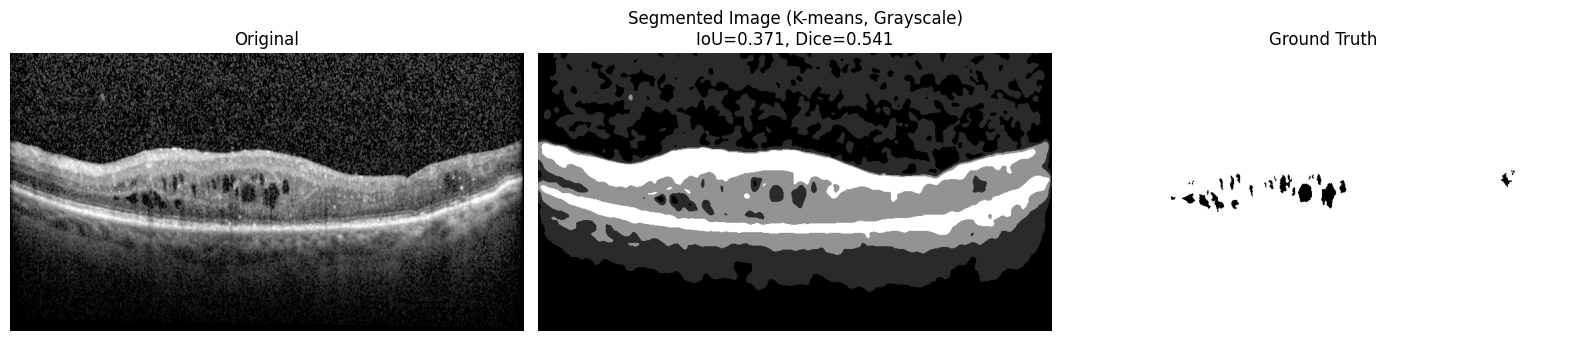

Processing: TRAINING3.tif


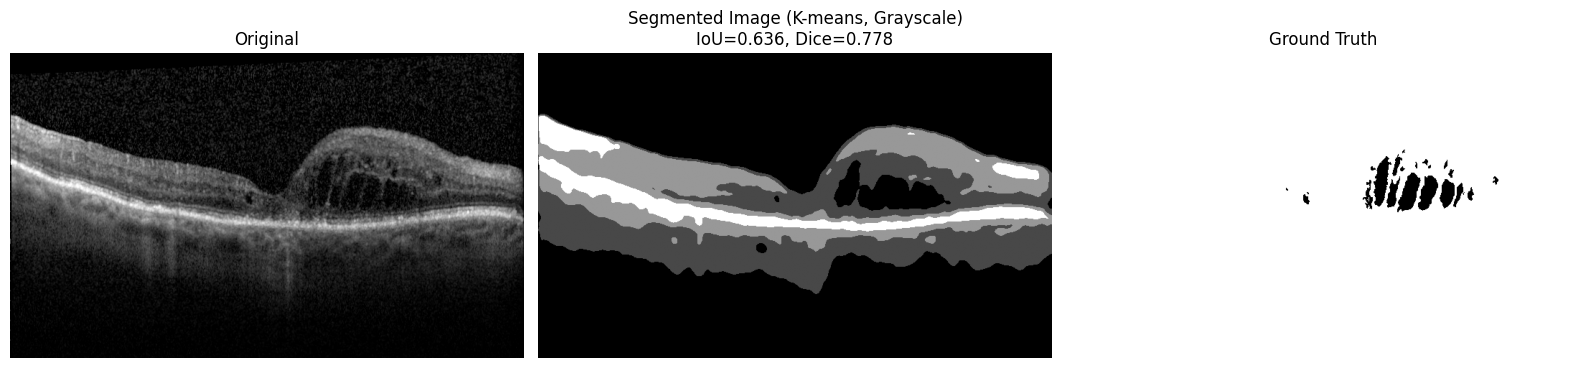

Processing: TRAINING4.tif


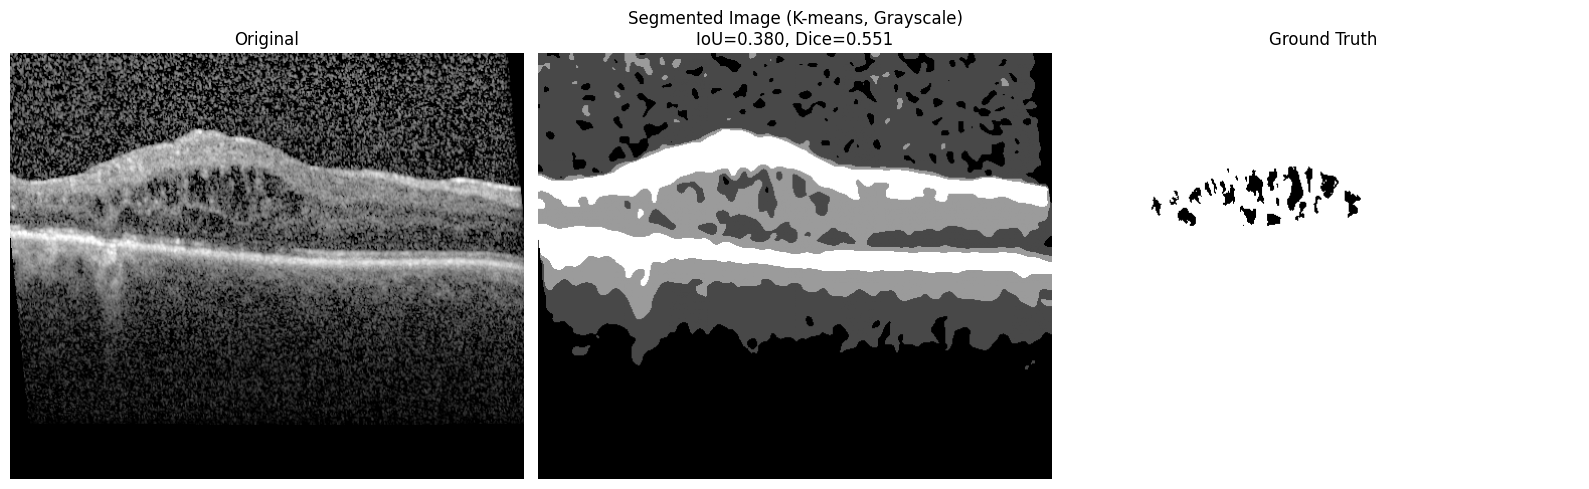

Processing: TRAINING5.tif


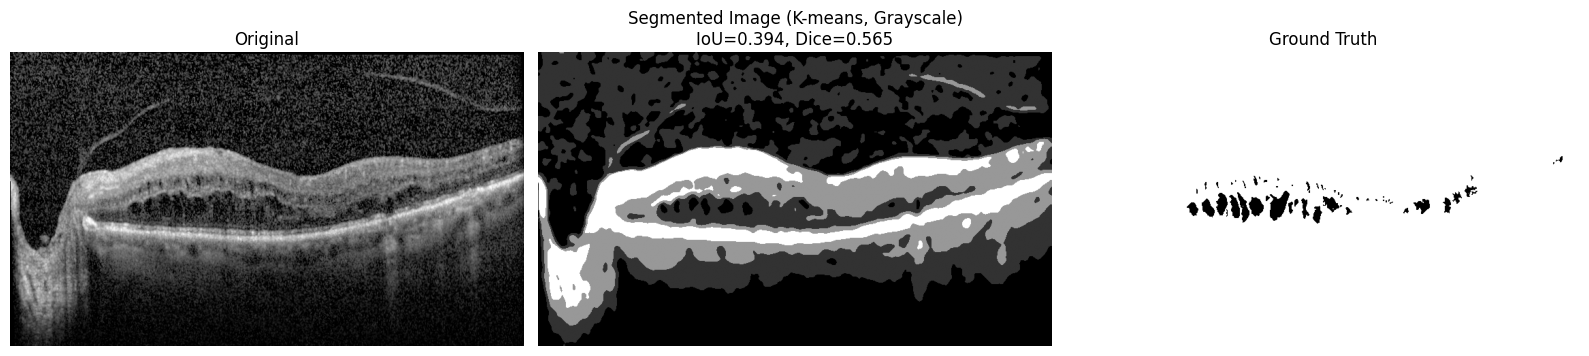

Processing: TRAINING6.tif


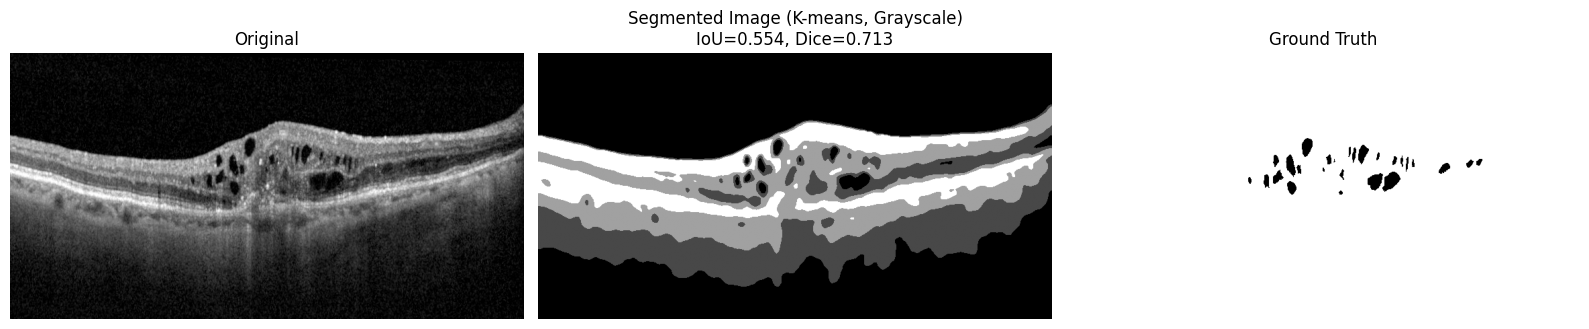

Processing: TRAINING7.tif


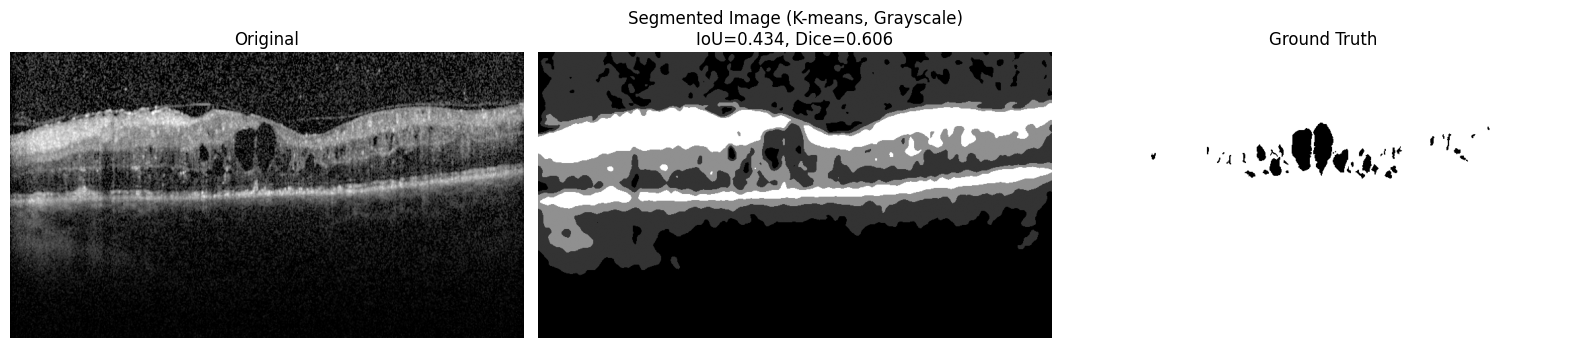

Processing: TRAINING8.tif


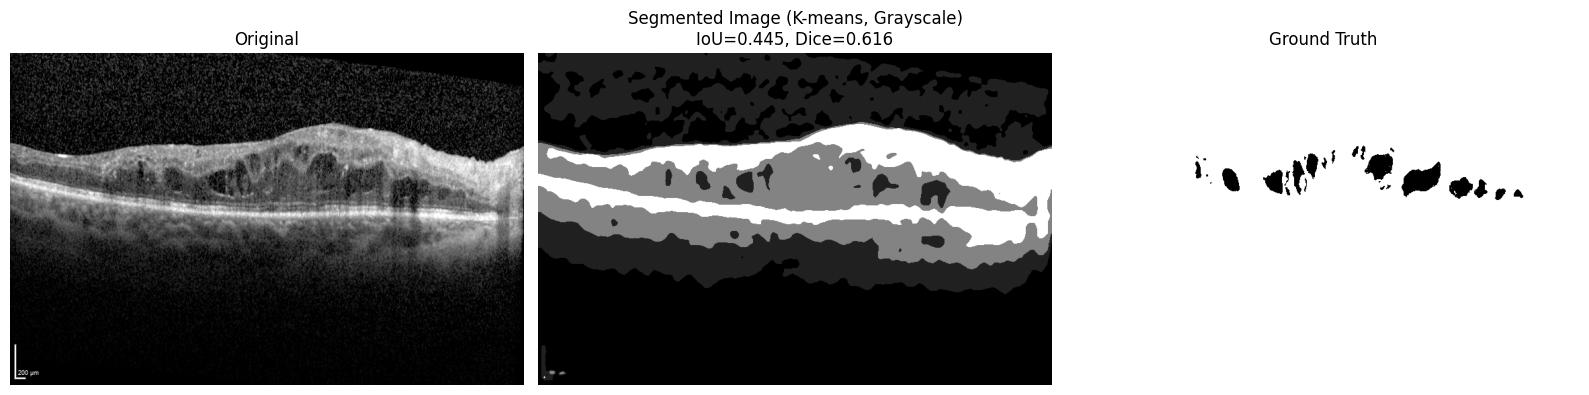

Processing: TRAINING9.tif


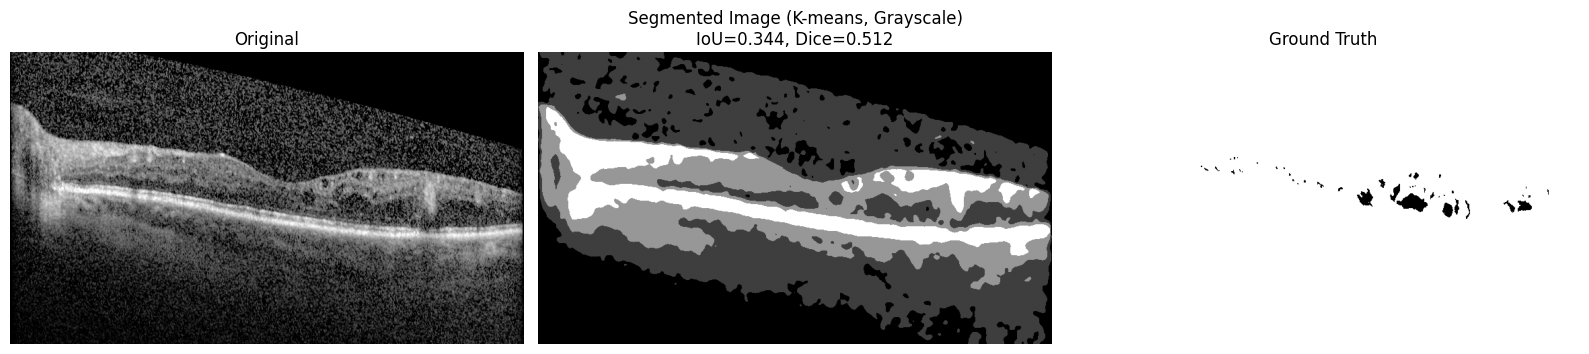


Average IoU: 0.4757 | Average Dice: 0.6380


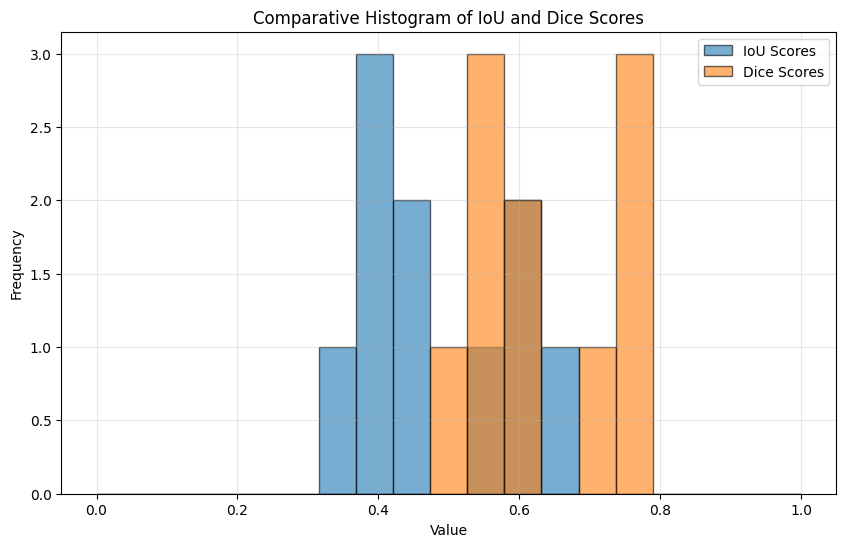

In [ ]:
import cv2
import os
import numpy as np
import matplotlib.pyplot as plt

from google.colab import drive
drive.mount('/content/drive')

# Paths
scan_dir = '/content/drive/MyDrive/data/OCT_Dataset/img_dir/'
gt_dir = '/content/drive/MyDrive/data/OCT_Dataset/ann_dir/'

# Defining Parameters
K = 4

# Functions
def preprocess_image(img):
    # Median, bilateral and non-local means filtering is used for preprocessing the images.
    median_img = cv2.medianBlur(img, 5)
    bilateral_img = cv2.bilateralFilter(median_img, d=9, sigmaColor=75, sigmaSpace=75)
    nlm_img = cv2.fastNlMeansDenoising(bilateral_img, None, h=10, templateWindowSize=7, searchWindowSize=21)
    return nlm_img

def kmeans_segmentation_basic(img, K=4, max_iters=100):
    # K-means used as a segmentation technique.

    # Flatten image
    Z = img.reshape(-1, 1).astype(np.float32)

    # Initialize cluster centers randomly
    np.random.seed(0)
    centers = np.random.choice(Z.flatten(), K, replace=False).reshape(K, 1)

    for i in range(max_iters):
        # Assign each pixel to the nearest cluster center
        distances = np.abs(Z - centers.T)
        labels = np.argmin(distances, axis=1)

        # Update cluster centers
        new_centers = np.array([
            Z[labels == k].mean() if np.any(labels == k) else centers[k][0]
            for k in range(K)
        ]).reshape(K, 1)

        # Check for convergence
        if np.allclose(centers, new_centers):
            break
        centers = new_centers

    # Identify the darkest cluster as cyst
    dark_cluster_label = np.argmin(centers)

    # Binary mask
    cyst_mask_binary = (labels == dark_cluster_label).reshape(img.shape).astype(np.uint8) * 255

    # Grayscale segmented image
    segmented_img_grayscale = np.array([centers[label][0] for label in labels], dtype=np.uint8).reshape(img.shape)

    # Colored visualization (manual color mapping)
    segmented_img_colored = np.zeros((*img.shape, 3), dtype=np.uint8)
    colors = np.linspace(0, 255, K).astype(np.uint8)
    for k in range(K):
        idx = labels.reshape(img.shape) == k
        if k == dark_cluster_label:
            segmented_img_colored[idx] = [255, 0, 0]  # Red for cysts
        else:
            color_val = int(colors[k])
            if k % 3 == 0: segmented_img_colored[idx] = [color_val, color_val, 0]
            elif k % 3 == 1: segmented_img_colored[idx] = [0, color_val, color_val]
            else: segmented_img_colored[idx] = [color_val, 0, color_val]

    return cyst_mask_binary, segmented_img_colored, segmented_img_grayscale

def calculate_iou(mask1, mask2):
    intersection = np.logical_and(mask1, mask2).sum()
    union = np.logical_or(mask1, mask2).sum()
    return intersection / union if union != 0 else 0

def calculate_dice(mask1, mask2):
    intersection = np.logical_and(mask1, mask2).sum()
    return (2 * intersection) / (mask1.sum() + mask2.sum()) if (mask1.sum() + mask2.sum()) != 0 else 0

# Loop to run for all images
files = sorted(os.listdir(scan_dir))
all_ious = []
all_dices = []

for image_name in files:
    print("Processing:", image_name)

    # Load grayscale image
    img_gray = cv2.imread(os.path.join(scan_dir, image_name), cv2.IMREAD_GRAYSCALE)

    # Preprocessing
    enhanced_img = preprocess_image(img_gray)

    # K-means segmentation
    cyst_mask_binary, segmented_img_colored, segmented_img_grayscale = kmeans_segmentation_basic(enhanced_img, K)

    # Load ground truth mask
    gt_mask = cv2.imread(os.path.join(gt_dir, image_name), cv2.IMREAD_GRAYSCALE)
    if gt_mask.shape != cyst_mask_binary.shape:
        gt_mask = cv2.resize(gt_mask, (cyst_mask_binary.shape[1], cyst_mask_binary.shape[0]), interpolation=cv2.INTER_NEAREST)
    if np.mean(gt_mask) < 128:
        gt_mask = cv2.bitwise_not(gt_mask)
    mask_gt = (gt_mask > 128).astype(bool)

    # Predicted mask
    mask_pred = (cyst_mask_binary > 0).astype(bool)

    # Metrics
    iou_score = calculate_iou(mask_pred, mask_gt)
    dice_score = calculate_dice(mask_pred, mask_gt)
    all_ious.append(iou_score)
    all_dices.append(dice_score)

    # Visualization
    plt.figure(figsize=(16,6))
    plt.subplot(1,3,1)
    plt.imshow(img_gray, cmap='gray')
    plt.title('Original')
    plt.axis('off')

    plt.subplot(1,3,2)
    plt.imshow(segmented_img_grayscale, cmap='gray')
    plt.title(f'Segmented Image (K-means, Grayscale)\nIoU={iou_score:.3f}, Dice={dice_score:.3f}')
    plt.axis('off')

    plt.subplot(1,3,3)
    plt.imshow(gt_mask, cmap='gray')
    plt.title('Ground Truth')
    plt.axis('off')

    plt.tight_layout()
    plt.show()

# Averaging Scores
avg_iou = np.mean(all_ious)
avg_dice = np.mean(all_dices)
print("\n" + "="*60)
print(f"Average IoU: {avg_iou:.4f} | Average Dice: {avg_dice:.4f}")
print("="*60)

# Comparative Histogram
plt.figure(figsize=(10,6))
bins = np.linspace(0, 1, 20)

plt.hist(all_ious, bins=bins, alpha=0.6, label='IoU Scores', edgecolor='black')
plt.hist(all_dices, bins=bins, alpha=0.6, label='Dice Scores', edgecolor='black')

plt.xlabel('Value')
plt.ylabel('Frequency')
plt.title('Comparative Histogram of IoU and Dice Scores')
plt.legend()
plt.grid(alpha=0.3)
plt.show()
